# Validation des schémas numériques et de la formule de Dupire

On teste le code de `src/dupire/` sur des données synthétiques, où la solution est connue :
1. EDP forward contre formule de Black-Scholes, à volatilité constante ;
2. comparaison des 5 schémas en temps, ordre en $\Delta t$ et temps de calcul ;
3. ordre en $\Delta K$ ;
4. aller-retour avec la formule de Dupire, sur une volatilité locale avec smile ;
5. sensibilité de la formule de Dupire au bruit sur les prix.

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("../src")
from dupire.black_scholes import bs_call_price
from dupire.pde_solver import solve_dupire_pde
from dupire.local_vol import local_vol_from_prices, fill_local_vol_surface, price_derivatives

## Paramètres

In [2]:
# Paramètres financiers
S0 = 100.0
r = 0.05
SIGMA0 = 0.20

# Grille de l'EDP
K_MAX = 300.0
T_MAX = 1.0
N_K = 150
N_T = 100

# Zone liquide, où l'on mesure l'erreur
K_BAS = 60.0
K_HAUT = 160.0

# Étude en temps
LISTE_N_T = [25, 50, 100, 200, 400]
N_T_REF = 1600

# Étude en espace
LISTE_N_K = [75, 150, 300, 600]
N_T_ESPACE = 200

# Bruit sur les prix : écart-type et graine
BRUIT = 0.005
GRAINE = 42


def vol_constante(K, t):
    return SIGMA0


def vol_smile(K, t):
    #Volatilité locale imposée : minimum en K = S0
    x = K / S0 - 1.0
    return 0.20 + 0.10 * np.exp(-0.5 * t) * x**2 / (0.05 + x**2)


def prix_bs(K):
    #Prix Black-Scholes à T_MAX sur la grille, avec C = S0 en K = 0
    C = np.zeros(len(K))
    C[0] = S0
    C[1:] = bs_call_price(S0, K[1:], T_MAX, r, 0.0, SIGMA0)
    return C


def erreur_l2(K, C, ref):
    #Erreur quadratique moyenne sur la zone liquide
    zone = (K >= K_BAS) & (K <= K_HAUT)
    return np.sqrt(np.mean((C[zone] - ref[zone]) ** 2))

## 1. EDP forward contre Black-Scholes

À volatilité constante $\sigma_0$, la solution de l'EDP forward
$$\frac{\partial C}{\partial T} = \frac{1}{2} \sigma_0^2 K^2 \frac{\partial^2 C}{\partial K^2} - r K \frac{\partial C}{\partial K}$$
doit redonner les prix de Black-Scholes.

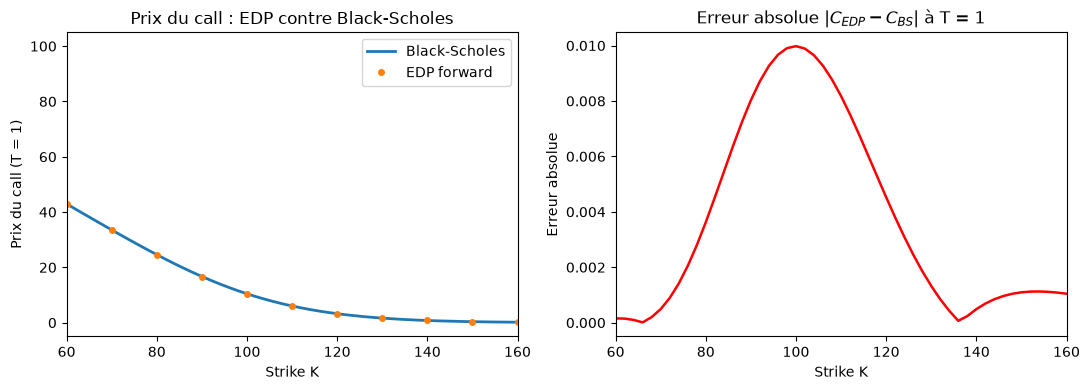

Erreur absolue maximale : 9.9786e-03, atteinte en K = 100
Erreur relative médiane : 0.0857 %


In [3]:
K, T, C_edp = solve_dupire_pde(S0, r, vol_constante, K_MAX, T_MAX, N_K, N_T, 0.5, 2)
C_bs = prix_bs(K)
erreur = np.abs(C_edp[-1] - C_bs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(K, C_bs, lw=2, label="Black-Scholes")
ax1.plot(K[::5], C_edp[-1, ::5], "o", markersize=4, label="EDP forward")
ax1.set_xlim(K_BAS, K_HAUT)
ax1.set_xlabel("Strike K")
ax1.set_ylabel("Prix du call (T = 1)")
ax1.set_title("Prix du call : EDP contre Black-Scholes")
ax1.legend()
ax2.plot(K, erreur, color="red", lw=1.8)
ax2.set_xlim(K_BAS, K_HAUT)
ax2.set_xlabel("Strike K")
ax2.set_ylabel("Erreur absolue")
ax2.set_title(r"Erreur absolue $|C_{EDP} - C_{BS}|$ à T = 1")
plt.tight_layout()
fig.savefig("../report/figures/fig1_edp_vs_bs.png", dpi=200)
plt.show()

zone = (K >= K_BAS) & (K <= K_HAUT)
print(f"Erreur absolue maximale : {np.max(erreur[zone]):.4e}, atteinte en K = {K[zone][np.argmax(erreur[zone])]:.0f}")
print(f"Erreur relative médiane : {np.median(erreur[zone] / C_bs[zone]) * 100:.4f} %")

## 2. Comparaison des schémas en temps

On compare les 5 variantes du $\theta$-schéma, avec $n_K = 150$ et $n_T = 100$ :
- **explicite** ($\theta = 0$) : stable seulement si $n_T \ge \sigma_0^2 n_K^2 T_{max}$, condition suffisante ;
- **implicite** ($\theta = 1$) : stable, ordre 1 en $\Delta t$ ;
- **Rannacher seul** : deux demi-pas implicites à chaque pas de temps, stable, ordre 1, deux fois plus de systèmes à résoudre ;
- **Crank-Nicolson** ($\theta = 1/2$) : ordre 2, avec ou sans deux pas de lissage de Rannacher au départ.

In [4]:
noms = ["Explicite", "Implicite", "Rannacher seul", "Crank-Nicolson sans Rannacher", "Crank-Nicolson avec Rannacher"]
thetas = [0.0, 1.0, 0.5, 0.5, 0.5]
rannacher = [0, 0, N_T, 0, 2]

print(f"Condition de stabilité de l'explicite : n_T >= {SIGMA0**2 * N_K**2 * T_MAX:.0f}, ici n_T = {N_T}")
print()
print(f"{'Schéma':32s}{'Erreur L2':>14s}{'Temps (ms)':>12s}")
for s in range(len(noms)):
    debut = time.perf_counter()
    K, T, C = solve_dupire_pde(S0, r, vol_constante, K_MAX, T_MAX, N_K, N_T, thetas[s], rannacher[s])
    temps = (time.perf_counter() - debut) * 1000
    err = erreur_l2(K, C[-1], C_bs)
    if err > 1e4:
        print(f"{noms[s]:32s}{'diverge':>14s}{temps:12.2f}")
    else:
        print(f"{noms[s]:32s}{err:14.4e}{temps:12.2f}")

Condition de stabilité de l'explicite : n_T >= 900, ici n_T = 100

Schéma                               Erreur L2  Temps (ms)
Explicite                              diverge        3.80
Implicite                           1.1038e-02        2.82
Rannacher seul                      7.8081e-03        5.07
Crank-Nicolson sans Rannacher       5.0889e-03        2.75
Crank-Nicolson avec Rannacher       5.1322e-03        3.61


Pour mesurer l'erreur en temps seule, on fait varier $n_T$ sur la même grille en strike. Les trois schémas sont comparés à la même référence : Crank-Nicolson avec Rannacher et $n_T = 1600$.

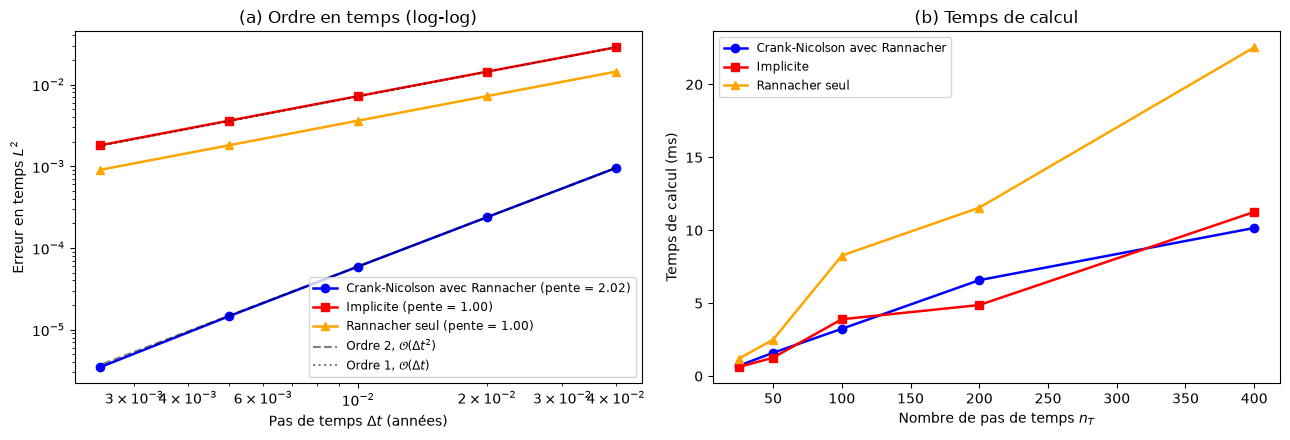

Pente Crank-Nicolson avec Rannacher : 2.02 (ordre 2 attendu)
Pente implicite                     : 1.00 (ordre 1 attendu)
Pente Rannacher seul                : 1.00 (ordre 1 attendu)


In [5]:
_, _, C_ref = solve_dupire_pde(S0, r, vol_constante, K_MAX, T_MAX, N_K, N_T_REF, 0.5, 2)

pas_dt = np.zeros(len(LISTE_N_T))
err_cn = np.zeros(len(LISTE_N_T))
err_imp = np.zeros(len(LISTE_N_T))
err_ran = np.zeros(len(LISTE_N_T))
cpu_cn = np.zeros(len(LISTE_N_T))
cpu_imp = np.zeros(len(LISTE_N_T))
cpu_ran = np.zeros(len(LISTE_N_T))

for i in range(len(LISTE_N_T)):
    n = LISTE_N_T[i]
    pas_dt[i] = T_MAX / n

    debut = time.perf_counter()
    K, T, C = solve_dupire_pde(S0, r, vol_constante, K_MAX, T_MAX, N_K, n, 0.5, 2)
    cpu_cn[i] = (time.perf_counter() - debut) * 1000
    err_cn[i] = erreur_l2(K, C[-1], C_ref[-1])

    debut = time.perf_counter()
    K, T, C = solve_dupire_pde(S0, r, vol_constante, K_MAX, T_MAX, N_K, n, 1.0, 0)
    cpu_imp[i] = (time.perf_counter() - debut) * 1000
    err_imp[i] = erreur_l2(K, C[-1], C_ref[-1])

    debut = time.perf_counter()
    K, T, C = solve_dupire_pde(S0, r, vol_constante, K_MAX, T_MAX, N_K, n, 0.5, n)
    cpu_ran[i] = (time.perf_counter() - debut) * 1000
    err_ran[i] = erreur_l2(K, C[-1], C_ref[-1])

# Pentes en échelle log-log
pente_cn = np.polyfit(np.log(pas_dt), np.log(err_cn), 1)[0]
pente_imp = np.polyfit(np.log(pas_dt), np.log(err_imp), 1)[0]
pente_ran = np.polyfit(np.log(pas_dt), np.log(err_ran), 1)[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.loglog(pas_dt, err_cn, "o-", color="blue", lw=1.8, label=f"Crank-Nicolson avec Rannacher (pente = {pente_cn:.2f})")
ax1.loglog(pas_dt, err_imp, "s-", color="red", lw=1.8, label=f"Implicite (pente = {pente_imp:.2f})")
ax1.loglog(pas_dt, err_ran, "^-", color="orange", lw=1.8, label=f"Rannacher seul (pente = {pente_ran:.2f})")
ax1.loglog(pas_dt, err_cn[0] * (pas_dt / pas_dt[0]) ** 2, "k--", alpha=0.5, label=r"Ordre 2, $\mathcal{O}(\Delta t^2)$")
ax1.loglog(pas_dt, err_imp[0] * (pas_dt / pas_dt[0]), "k:", alpha=0.5, label=r"Ordre 1, $\mathcal{O}(\Delta t)$")
ax1.set_xlabel(r"Pas de temps $\Delta t$ (années)")
ax1.set_ylabel(r"Erreur en temps $L^2$")
ax1.set_title("(a) Ordre en temps (log-log)")
ax1.legend(fontsize=8.5)
ax2.plot(LISTE_N_T, cpu_cn, "o-", color="blue", lw=1.8, label="Crank-Nicolson avec Rannacher")
ax2.plot(LISTE_N_T, cpu_imp, "s-", color="red", lw=1.8, label="Implicite")
ax2.plot(LISTE_N_T, cpu_ran, "^-", color="orange", lw=1.8, label="Rannacher seul")
ax2.set_xlabel("Nombre de pas de temps $n_T$")
ax2.set_ylabel("Temps de calcul (ms)")
ax2.set_title("(b) Temps de calcul")
ax2.legend(fontsize=8.5)
plt.tight_layout()
fig.savefig("../report/figures/fig2_consistance_temps_cpu.png", dpi=200)
plt.show()

print(f"Pente Crank-Nicolson avec Rannacher : {pente_cn:.2f} (ordre 2 attendu)")
print(f"Pente implicite                     : {pente_imp:.2f} (ordre 1 attendu)")
print(f"Pente Rannacher seul                : {pente_ran:.2f} (ordre 1 attendu)")

## 3. Ordre en espace

Les différences centrées en $K$ sont d'ordre 2. On fait varier $n_K$ avec $n_T = 200$ fixé, en Crank-Nicolson avec Rannacher, et on mesure l'erreur contre Black-Scholes. Sur ces grilles, $S_0$ est toujours un nœud. L'ordre 2 donne un rapport d'erreur de 4 quand $\Delta K$ est divisé par 2.

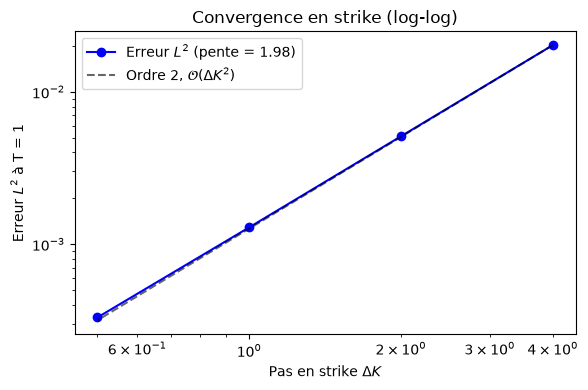

n_K =  75, dK = 4.00 : erreur 2.025e-02
n_K = 150, dK = 2.00 : erreur 5.104e-03
n_K = 300, dK = 1.00 : erreur 1.288e-03
n_K = 600, dK = 0.50 : erreur 3.300e-04
Pente : 1.98 (ordre 2 attendu)
Rapport d'erreur entre n_K = 75 et n_K = 150 : 3.97 (4 attendu)
Rapport d'erreur entre n_K = 150 et n_K = 300 : 3.96 (4 attendu)
Rapport d'erreur entre n_K = 300 et n_K = 600 : 3.90 (4 attendu)


In [6]:
pas_dK = np.zeros(len(LISTE_N_K))
err_dK = np.zeros(len(LISTE_N_K))

for i in range(len(LISTE_N_K)):
    K, T, C = solve_dupire_pde(S0, r, vol_constante, K_MAX, T_MAX, LISTE_N_K[i], N_T_ESPACE, 0.5, 2)
    pas_dK[i] = K[1] - K[0]
    err_dK[i] = erreur_l2(K, C[-1], prix_bs(K))

pente_dK = np.polyfit(np.log(pas_dK), np.log(err_dK), 1)[0]

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(pas_dK, err_dK, "o-", color="blue", label=f"Erreur $L^2$ (pente = {pente_dK:.2f})")
ax.loglog(pas_dK, err_dK[0] * (pas_dK / pas_dK[0]) ** 2, "k--", alpha=0.6, label=r"Ordre 2, $\mathcal{O}(\Delta K^2)$")
ax.set_xlabel(r"Pas en strike $\Delta K$")
ax.set_ylabel("Erreur $L^2$ à T = 1")
ax.set_title("Convergence en strike (log-log)")
ax.legend()
plt.tight_layout()
fig.savefig("../report/figures/fig3_convergence_spatiale.png", dpi=200)
plt.show()

for i in range(len(LISTE_N_K)):
    print(f"n_K = {LISTE_N_K[i]:3d}, dK = {pas_dK[i]:.2f} : erreur {err_dK[i]:.3e}")
print(f"Pente : {pente_dK:.2f} (ordre 2 attendu)")
for i in range(len(LISTE_N_K) - 1):
    print(f"Rapport d'erreur entre n_K = {LISTE_N_K[i]} et n_K = {LISTE_N_K[i + 1]} : {err_dK[i] / err_dK[i + 1]:.2f} (4 attendu)")

## 4. Aller-retour avec la formule de Dupire

On impose une volatilité locale avec smile :
$$\sigma_{loc}(K, T) = 0.20 + 0.10 \, e^{-0.5 T} \frac{(K/S_0 - 1)^2}{0.05 + (K/S_0 - 1)^2}$$

L'EDP forward donne les prix $C(K, T)$, puis la formule de Dupire, discrétisée par différences finies, redonne la volatilité :
$$\sigma_{loc}^2(K, T) = \frac{\frac{\partial C}{\partial T} + r K \frac{\partial C}{\partial K}}{\frac{1}{2} K^2 \frac{\partial^2 C}{\partial K^2}}$$

T = 0.25 : erreur relative médiane 0.019 %, maximale 0.142 %
T = 0.50 : erreur relative médiane 0.005 %, maximale 0.007 %
T = 0.75 : erreur relative médiane 0.002 %, maximale 0.003 %
T = 1.00 : erreur relative médiane 0.001 %, maximale 0.002 %


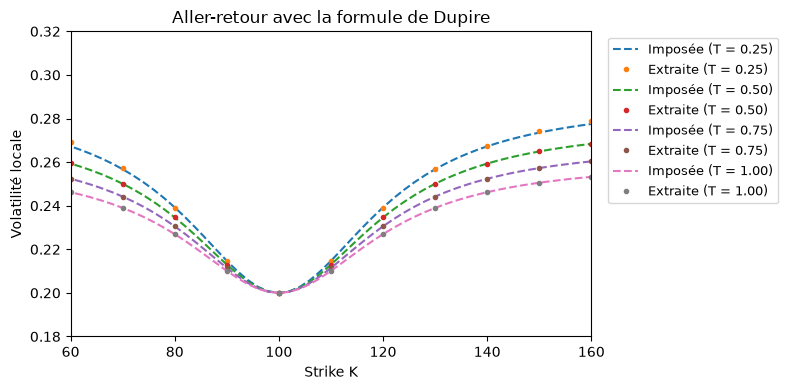

In [7]:
K, T, C = solve_dupire_pde(S0, r, vol_smile, K_MAX, T_MAX, N_K, N_T, 0.5, 2)
sigma_ext = local_vol_from_prices(K, T, C, r)
sigma_ext = fill_local_vol_surface(K, T, sigma_ext)

maturites = [0.25, 0.50, 0.75, 1.0]
zone_ar = (K >= 70) & (K <= 140)

fig, ax = plt.subplots(figsize=(8, 4))
for t_vise in maturites:
    i = np.argmin(np.abs(T - t_vise))
    ax.plot(K, vol_smile(K, T[i]), "--", label=f"Imposée (T = {T[i]:.2f})")
    ax.plot(K[::5], sigma_ext[i, ::5], "o", markersize=3, label=f"Extraite (T = {T[i]:.2f})")
    vraie = vol_smile(K[zone_ar], T[i])
    err_rel = np.abs(sigma_ext[i, zone_ar] - vraie) / vraie
    print(f"T = {T[i]:.2f} : erreur relative médiane {np.median(err_rel) * 100:.3f} %, maximale {np.max(err_rel) * 100:.3f} %")
ax.set_xlim(K_BAS, K_HAUT)
ax.set_ylim(0.18, 0.32)
ax.set_xlabel("Strike K")
ax.set_ylabel("Volatilité locale")
ax.set_title("Aller-retour avec la formule de Dupire")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
fig.savefig("../report/figures/fig4_aller_retour_dupire.png", dpi=200)
plt.show()

## 5. Sensibilité au bruit

Les prix de marché sont bruités (fourchette bid-ask, cotation par ticks). La formule de Dupire contient au dénominateur la dérivée seconde
$$\frac{\partial^2 C}{\partial K^2} \approx \frac{C(K+\Delta K) - 2C(K) + C(K-\Delta K)}{\Delta K^2}$$
Un bruit d'amplitude $\varepsilon$ sur les prix donne donc une erreur d'ordre $\varepsilon / \Delta K^2$ sur cette dérivée. On ajoute aux prix un bruit gaussien d'écart-type 0,005 (un demi-centime) et on applique la formule sans lissage.

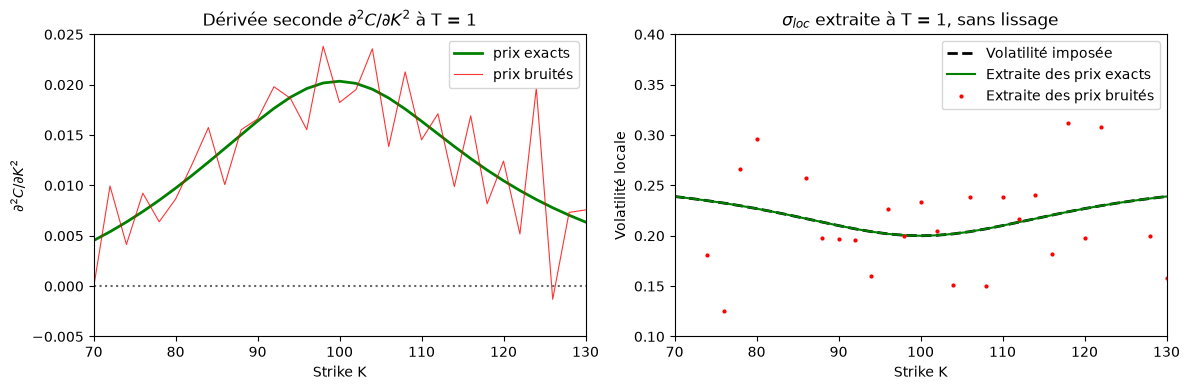

T = 1, K entre 70 et 130 : 31 points
Points rejetés par la formule (NaN)   : 5
Points hors du cadre de la figure     : 1
Erreur relative sur les autres points : médiane 16.9 %, maximale 87.3 %


In [8]:
np.random.seed(GRAINE)
C_bruite = np.maximum(C + np.random.normal(0.0, BRUIT, C.shape), 0.0)
sigma_bruite = local_vol_from_prices(K, T, C_bruite, r)

_, _, d2C = price_derivatives(K, T, C)
_, _, d2C_bruite = price_derivatives(K, T, C_bruite)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(K, d2C[-1], "g-", lw=2, label="prix exacts")
ax1.plot(K, d2C_bruite[-1], "r-", lw=0.8, alpha=0.8, label="prix bruités")
ax1.axhline(0, color="black", linestyle=":", alpha=0.6)
ax1.set_xlim(70, 130)
ax1.set_ylim(-0.005, 0.025)
ax1.set_xlabel("Strike K")
ax1.set_ylabel(r"$\partial^2 C / \partial K^2$")
ax1.set_title(r"Dérivée seconde $\partial^2 C / \partial K^2$ à T = 1")
ax1.legend()
ax2.plot(K, vol_smile(K, 1.0), "k--", lw=2, label="Volatilité imposée")
ax2.plot(K, sigma_ext[-1], "g-", lw=1.5, label="Extraite des prix exacts")
ax2.plot(K, sigma_bruite[-1], "r.", markersize=4, label="Extraite des prix bruités")
ax2.set_xlim(70, 130)
ax2.set_ylim(0.10, 0.40)
ax2.set_xlabel("Strike K")
ax2.set_ylabel("Volatilité locale")
ax2.set_title(r"$\sigma_{loc}$ extraite à T = 1, sans lissage")
ax2.legend()
plt.tight_layout()
fig.savefig("../report/figures/fig5_sensibilite_bruit.png", dpi=200)
plt.show()

zone_b = (K >= 70) & (K <= 130)
sigma_b = sigma_bruite[-1, zone_b]
vraie = vol_smile(K[zone_b], 1.0)
ok = np.isfinite(sigma_b)
err_rel = np.abs(sigma_b[ok] - vraie[ok]) / vraie[ok]
hors_cadre = np.sum((sigma_b[ok] < 0.10) | (sigma_b[ok] > 0.40))
print(f"T = 1, K entre 70 et 130 : {len(sigma_b)} points")
print(f"Points rejetés par la formule (NaN)   : {np.sum(~ok)}")
print(f"Points hors du cadre de la figure     : {hors_cadre}")
print(f"Erreur relative sur les autres points : médiane {np.median(err_rel) * 100:.1f} %, maximale {np.max(err_rel) * 100:.1f} %")

## Conclusion

**EDP contre Black-Scholes.** À volatilité constante, l'erreur maximale vaut $9{,}98 \cdot 10^{-3}$. Elle est atteinte à la monnaie. L'erreur relative médiane vaut 0,086 %.

**Schémas.** L'explicite diverge car $n_T = 100$ est très en dessous du seuil de 900 pas. L'implicite et Rannacher seul sont stables et moins précis. Les deux Crank-Nicolson ont la même erreur à cette résolution. Rannacher seul coûte environ deux fois plus cher que les autres.

**Ordres.** En temps, les pentes valent 2,02 pour Crank-Nicolson, 1,00 pour l'implicite et 1,00 pour Rannacher seul. En espace, la pente vaut 1,98 et les rapports d'erreur sont proches de 4. Ces valeurs confirment les ordres attendus.

**Aller-retour.** La formule de Dupire retrouve la volatilité imposée à 0,001 % près à $T = 1$ (erreur médiane). L'erreur maximale est de 0,14 % à $T = 0{,}25$. Ce test est favorable car les prix ne contiennent aucun bruit et viennent de la même grille que les dérivées.

**Bruit.** Avec un bruit de 0,005 sur les prix, 5 points sur 31 sont rejetés à $T = 1$ et l'erreur médiane passe à 16,9 % sur les autres points. Il faut donc lisser les données réelles avant d'appliquer la formule de Dupire (notebook 2).